# Import de bibliotecas

In [59]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Definição e teste de imagens

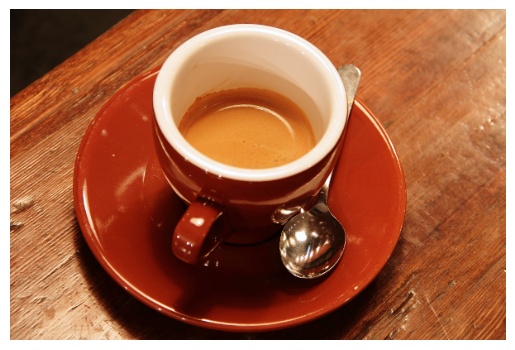

In [60]:
img = data.coffee()
plt.axis('off')
plt.imshow(img)

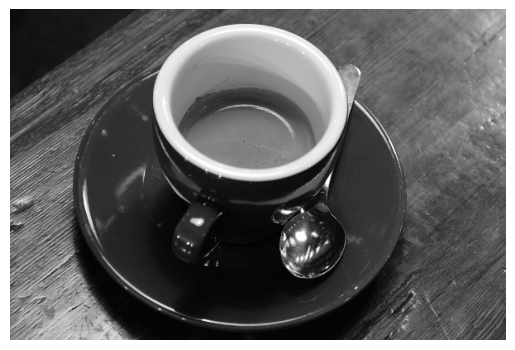

In [61]:
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.axis('off')
plt.imshow(img_gray, cmap='gray')

# Funções:

## Plotting de imagens

In [62]:
def implot(img, img_filtrada, msg):
  plt.figure(figsize=(15, 15))

  plt.subplot(1, 2, 1)
  plt.imshow(img, cmap='gray')
  plt.title('Original')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(img_filtrada, cmap='gray')
  plt.title('Filtrada ' + msg)
  plt.axis('off')

## Média

In [63]:
def media(img, kernelsize):
  img_media = np.zeros((img.shape[0] - kernelsize, img.shape[1] - kernelsize))

  altura = img.shape[0]
  largura = img.shape[1]

  for y in range(0, altura - kernelsize):
    for x in range(0, largura - kernelsize):
      img_media[y, x] = media_pixel(img, (y, x), kernelsize)

  return img_media

def media_pixel(img, pos, kernelsize):
  result = np.int32(0)
  for y in range(0, kernelsize):
    img_y = pos[0] + y

    for x in range(0, kernelsize):
      img_x = pos[1] + x

      result += img[img_y, img_x]

  return result/(kernelsize*kernelsize)

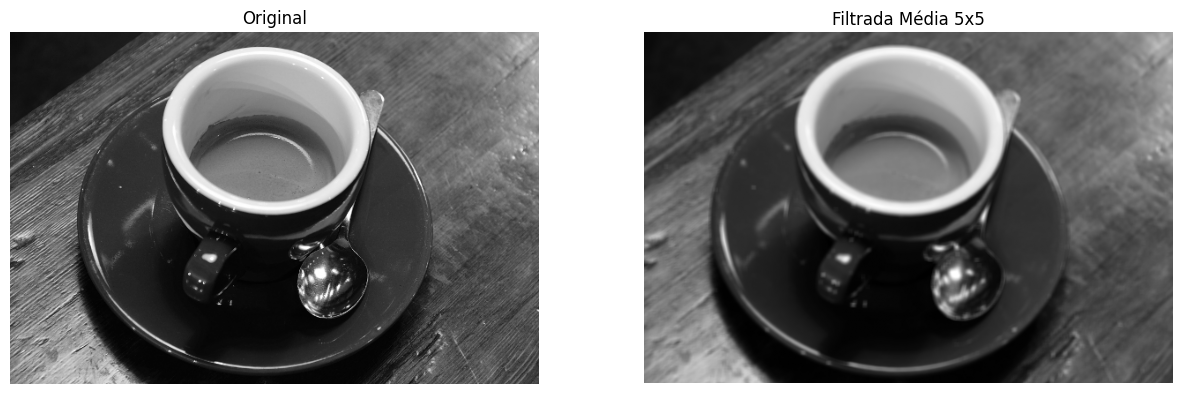

In [64]:
kernelsize = 5

img_media = media(img_gray, kernelsize)
msg_media = 'Média ' + str(kernelsize) + 'x' + str(kernelsize)
implot(img_gray, img_media, msg_media)

## Mediana

In [65]:
def mediana(img, kernelsize):
  img_mediana = np.zeros((img.shape[0] - kernelsize, img.shape[1] - kernelsize))

  altura = img.shape[0]
  largura = img.shape[1]

  for y in range(0, altura - kernelsize):
    for x in range(0, largura - kernelsize):
      img_mediana[y, x] = mediana_pixel(img, (y, x), kernelsize)

  return img_mediana

def mediana_pixel(img, pos, kernelsize):
  result = np.array([])
  for y in range(0, kernelsize):
    img_y = pos[0] + y

    for x in range(0, kernelsize):
      img_x = pos[1] + x

      result = np.append(result, img[img_y, img_x])

  result = np.sort(result)

  meio = kernelsize * kernelsize / 2
  if kernelsize % 2 == 0:
    return (result[meio-1] + result[meio]) / 2
  else:
    meio = round(meio)
    return result[meio]

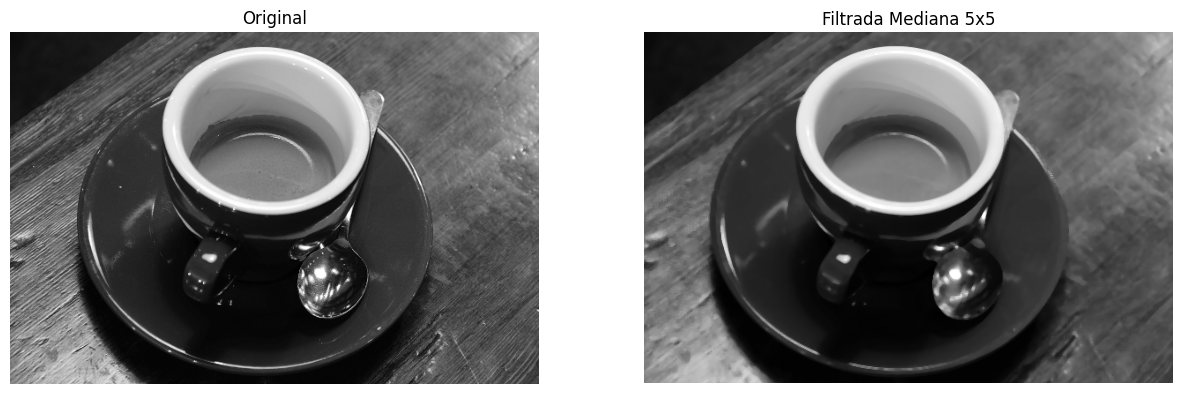

In [66]:
kernelsize = 5

img_mediana = mediana(img_gray, kernelsize)
msg_mediana = 'Mediana ' + str(kernelsize) + 'x' + str(kernelsize)
implot(img_gray, img_mediana, msg_mediana)

## Moda

In [67]:
def moda(img, kernelsize):
  img_moda = np.zeros((img.shape[0] - kernelsize, img.shape[1] - kernelsize))

  altura = img.shape[0]
  largura = img.shape[1]

  for y in range(0, altura - kernelsize):
    for x in range(0, largura - kernelsize):
      img_moda[y, x] = moda_pixel(img, (y, x), kernelsize)

  return img_moda

def moda_pixel(img, pos, kernelsize):
  result = np.array([], dtype=np.int64)
  for y in range(0, kernelsize):
    img_y = pos[0] + y

    for x in range(0, kernelsize):
      img_x = pos[1] + x

      result = np.append(result, img[img_y, img_x])

  moda = np.bincount(result).argmax()
  return moda

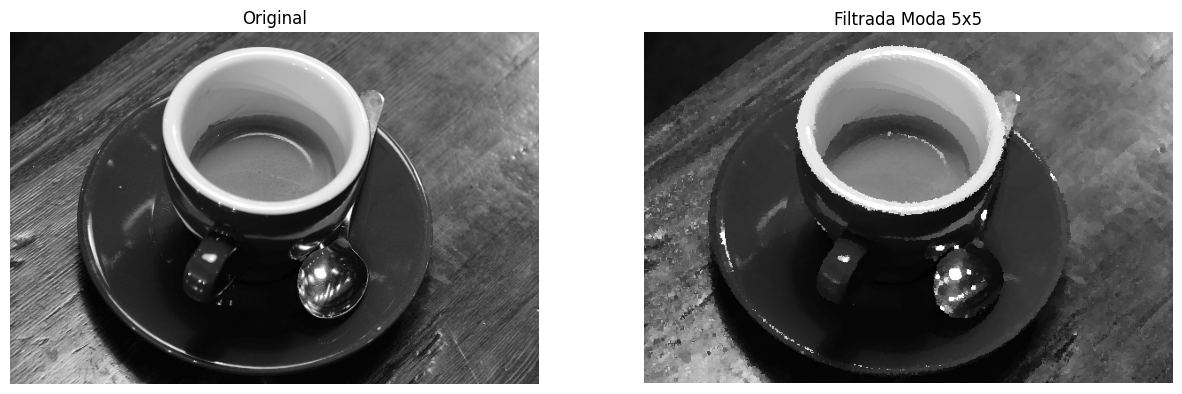

In [68]:
kernelsize = 5

img_moda = moda(img_gray, kernelsize)
msg_moda = 'Moda ' + str(kernelsize) + 'x' + str(kernelsize)
implot(img_gray, img_moda, msg_moda)

## Máxima

In [69]:
def maxima(img, kernelsize):
  img_maxima = np.zeros((img.shape[0] - kernelsize, img.shape[1] - kernelsize))

  altura = img.shape[0]
  largura = img.shape[1]

  for y in range(0, altura - kernelsize):
    for x in range(0, largura - kernelsize):
      img_maxima[y, x] = maxima_pixel(img, (y, x), kernelsize)

  return img_maxima

def maxima_pixel(img, pos, kernelsize):
  result = np.array([], dtype=np.int64)
  for y in range(0, kernelsize):
    img_y = pos[0] + y

    for x in range(0, kernelsize):
      img_x = pos[1] + x

      result = np.append(result, img[img_y, img_x])

  result = np.sort(result)
  maxima = np.flip(result)[0]
  return maxima

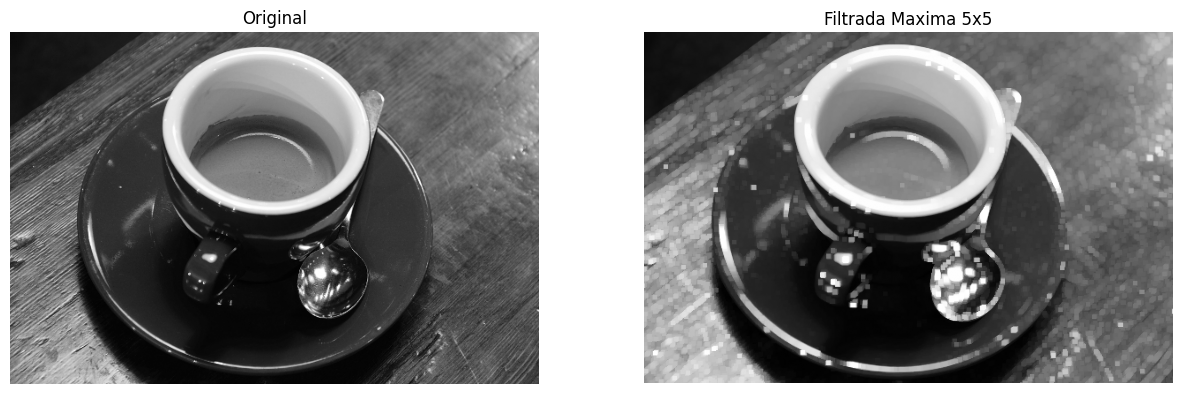

In [70]:
kernelsize = 5

img_maxima = maxima(img_gray, kernelsize)
msg_maxima = 'Maxima ' + str(kernelsize) + 'x' + str(kernelsize)
implot(img_gray, img_maxima, msg_maxima)